# Image formation, filtering and edges

This notebook builds the first layer of a robot's vision stack from first principles: how a 3D
world becomes a 2D image, how pixels and colours are represented, and how the classic low-level
operators (convolution, denoising filters, gradients, Canny edges) behave on real data.

**What it does**

1. Implements the pinhole camera model on a synthetic 3D scene, checks it against
   `cv2.projectPoints`, and visualises focal length, perspective and lens distortion.
2. Loads a real handheld RGB-D camera frame (TUM RGB-D `fr1_desk`, Kinect v1), selects the sharpest
   frame with the variance-of-Laplacian blur measure, and compares colour spaces under illumination change.
3. Shows aliasing when downsampling without a low-pass filter.
4. Implements 2D convolution from scratch (direct and separable) and benchmarks it against OpenCV.
5. Compares box / Gaussian / median / bilateral / non-local-means denoising with PSNR and SSIM.
6. Computes Sobel gradients and Canny edges, and **measures** Canny's edge F1 score against
   ground-truth edges as a function of noise, pre-blur and thresholds.

**What you'll learn**

- the projection equation $\lambda\,\tilde{\mathbf{u}} = K[R\,|\,\mathbf{t}]\tilde{\mathbf{X}}$ and the OpenCV camera conventions
- why focal length and camera distance are not interchangeable (perspective)
- the Brown-Conrady distortion model (barrel / pincushion)
- why hue-based thresholds survive exposure changes better than RGB thresholds
- the cost of convolution, $O(k^2)$ vs $O(2k)$ for separable kernels
- which filter to use for which noise, and why Canny needs a pre-blur

**Prerequisites**: NumPy, basic linear algebra (matrix-vector products, homogeneous coordinates).
Data: `make data-01_classical_cv` (TUM RGB-D `fr1_desk`, CC BY 4.0). Everything runs on the CPU in well under a minute.

## 0. Setup

`cvlab.device.setup()` seeds all random number generators and prints the software and hardware
versions, so the outputs committed with this notebook can be traced to the machine that produced them.
All paths are resolved relative to the repository root with `cvlab.io`.

In [1]:
# --- Setup: imports, seeding, device summary and repo-relative paths ---
# This notebook only needs NumPy/OpenCV on the CPU; the device summary is printed for traceability.
import time
from io import BytesIO

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image as IPImage
from IPython.display import display

from cvlab import device as cvdevice
from cvlab import geometry, io, metrics, tum, viz
from cvlab.bench import benchmark

device = cvdevice.setup(seed=0)
viz.set_style()
cv2.setRNGSeed(0)
rng = np.random.default_rng(0)

PROJECT = "01_classical_cv"
ROOT = io.repo_root()
TUM_DIR = io.data_dir("tum", "fr1_desk", "rgbd_dataset_freiburg1_desk")
RESULTS_DIR = io.project_dir(PROJECT) / "results"
RESULTS_DIR.mkdir(exist_ok=True)
results = {}  # every measured number ends up here and in results/nb01_filtering_edges.json
T_START = time.perf_counter()  # wall-clock start; the notebook runtime is reported in the summary cell


def show_jpeg(fig, quality=80):
    # Photo-like figures are embedded as JPEG (several times smaller than PNG) so the
    # committed notebook stays small; line plots are shown as PNG with plt.show().
    buf = BytesIO()
    fig.savefig(buf, format="jpeg", pil_kwargs={"quality": quality})
    plt.close(fig)
    display(IPImage(buf.getvalue()))

print("TUM sequence:", TUM_DIR.relative_to(ROOT), "| exists:", TUM_DIR.is_dir())
print("OpenCV threads:", cv2.getNumThreads())

python 3.12.16 | torch 2.11.0+cu128 (CUDA 12.8) | torchvision 0.26.0+cu128 | numpy 2.5.4 | opencv 5.0.0
device: cuda | GPU: NVIDIA GeForce RTX 5060 Laptop GPU (7.53 GB, sm_120)
TUM sequence: data/tum/fr1_desk/rgbd_dataset_freiburg1_desk | exists: True
OpenCV threads: 24


## 1. Image formation: the pinhole camera

A camera maps a 3D point $\mathbf{X}_w$ (world frame) to a pixel $(u, v)$ in three steps:

1. **Rigid transform** into the camera frame: $\mathbf{X}_c = R\,\mathbf{X}_w + \mathbf{t}$, i.e. $\mathbf{X}_c = T_{cw}\mathbf{X}_w$.
2. **Perspective division** onto the normalised image plane: $x = X_c / Z_c,\; y = Y_c / Z_c$.
3. **Intrinsics** convert metres on the normalised plane to pixels:

$$
\lambda \begin{bmatrix} u \\ v \\ 1 \end{bmatrix} =
\underbrace{\begin{bmatrix} f_x & 0 & c_x \\ 0 & f_y & c_y \\ 0 & 0 & 1 \end{bmatrix}}_{K}
\begin{bmatrix} R & \mathbf{t} \end{bmatrix}
\begin{bmatrix} X_w \\ Y_w \\ Z_w \\ 1 \end{bmatrix},
\qquad \lambda = Z_c .
$$

Conventions used throughout this repository (`cvlab.geometry`): the OpenCV camera frame has
**x right, y down, z forward**; `T_wc` is the camera pose (camera-to-world) and `T_cw = inv(T_wc)`
are the extrinsics used for projection. The horizontal field of view follows from the focal length:
$\mathrm{FOV}_x = 2\arctan\!\left(\frac{W}{2 f_x}\right)$.

We build a tiny world (z up, metres): a 2 m x 2 m floor grid and a 0.5 m cube, and place a 60 degree
camera with `look_at`.

In [2]:
# --- Build a synthetic 3D scene (line segments) and a camera that looks at it ---
# Every object is a set of 3D line segments with shape (S, 2, 3): S segments, 2 endpoints, xyz in metres.
def cube_segments(center, size):
    h = size / 2.0
    corners = np.array([[x, y, z] for x in (-h, h) for y in (-h, h) for z in (-h, h)]) + center
    # an edge joins two corners that differ in exactly one coordinate
    edges = [(i, j) for i in range(8) for j in range(i + 1, 8)
             if np.sum(np.abs(corners[i] - corners[j]) > 1e-9) == 1]
    return np.array([[corners[i], corners[j]] for i, j in edges])

def grid_segments(half=1.0, step=0.25):
    ticks = np.arange(-half, half + 1e-9, step)
    segs = [[[t, -half, 0.0], [t, half, 0.0]] for t in ticks]
    segs += [[[-half, t, 0.0], [half, t, 0.0]] for t in ticks]
    return np.array(segs)

cube = cube_segments(np.array([0.0, 0.0, 0.25]), 0.5)   # (12, 2, 3)
floor = grid_segments()                                  # (18, 2, 3)
target = np.array([0.0, 0.0, 0.25])
eye = np.array([2.0, -2.4, 1.5])

cam = geometry.PinholeCamera.from_fov(640, 480, fov_x_deg=60.0)
T_wc = geometry.look_at(eye, target, up=(0.0, 0.0, 1.0))  # camera pose, OpenCV axes
T_cw = geometry.invert_T(T_wc)                            # extrinsics: world -> camera
print("K =\n", cam.K.round(2))
print("FOV (x, y) [deg]:", np.round(cam.fov_deg, 1), "| camera centre in world [m]:", T_wc[:3, 3])

K =
 [[554.26   0.   319.5 ]
 [  0.   554.26 239.5 ]
 [  0.     0.     1.  ]]
FOV (x, y) [deg]: [60.  46.8] | camera centre in world [m]: [ 2.  -2.4  1.5]


Projection is a few lines with `cvlab.geometry.project`. Straight 3D lines stay straight under an
ideal pinhole projection, so projecting the two endpoints of each segment is enough (we will need
dense sampling once lens distortion bends the lines). Points with $Z_c \le 0$ are behind the camera
and must be discarded before the division by $Z_c$.

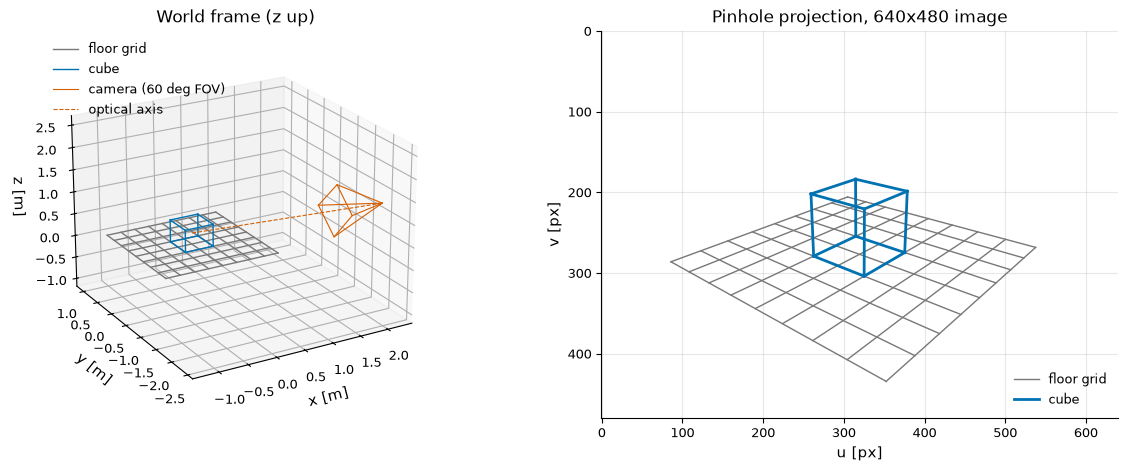

In [3]:
# --- Project the scene and draw the camera's view next to a 3D overview ---
# project_segments samples n points per segment (n=2 is exact for a pinhole camera without distortion).
def project_segments(segs, K, T_cw, n=2, dist=None):
    t = np.linspace(0.0, 1.0, n)[None, :, None]
    pts = segs[:, :1] * (1 - t) + segs[:, 1:] * t               # (S, n, 3) world points
    P_c = geometry.transform_points(T_cw, pts.reshape(-1, 3))   # (S*n, 3) camera frame
    if dist is None:
        uv, z = geometry.project(P_c, K)
    else:  # OpenCV applies the distortion model; its output is (N, 1, 2)
        uv = cv2.projectPoints(P_c, np.zeros(3), np.zeros(3), K, dist)[0].reshape(-1, 2)
        z = P_c[:, 2]
    return uv.reshape(len(segs), n, 2), z.reshape(len(segs), n)

def draw_segments(ax, uv, z, cam, color, lw=1.5, label=None):
    first = True
    for line, depth in zip(uv, z):
        if np.all(depth > 0.05):  # skip segments that touch the region behind the camera
            ax.plot(line[:, 0], line[:, 1], color=color, lw=lw, label=label if first else None)
            first = False
    ax.set_xlim(-0.5, cam.width - 0.5)
    ax.set_ylim(cam.height - 0.5, -0.5)  # image convention: v grows downwards
    ax.set_aspect("equal")
    ax.set_xlabel("u [px]")
    ax.set_ylabel("v [px]")

fig = plt.figure(figsize=(12, 4.6))
ax3 = fig.add_subplot(1, 2, 1, projection="3d")
for segs, c, name in [(floor, viz.color(7, True), "floor grid"), (cube, viz.color(0, True), "cube")]:
    for k, s in enumerate(segs):
        ax3.plot(*s.T, color=c, lw=1.0, label=name if k == 0 else None)
viz.plot_camera_frustums(ax3, T_wc[None], cam.K, cam.width, cam.height, scale=0.8,
                         color_rgb=viz.color(5, True), label="camera (60 deg FOV)")
ax3.plot(*np.stack([eye, target]).T, "--", color=viz.color(5, True), lw=0.8, label="optical axis")
ax3.set_xlabel("x [m]")
ax3.set_ylabel("y [m]")
ax3.set_zlabel("z [m]")
ax3.set_title("World frame (z up)")
viz.set_axes_equal(ax3)
ax3.view_init(elev=22, azim=-120)
ax3.legend(loc="upper left")
ax = fig.add_subplot(1, 2, 2)
draw_segments(ax, *project_segments(floor, cam.K, T_cw), cam, viz.color(7, True), 1.0, "floor grid")
draw_segments(ax, *project_segments(cube, cam.K, T_cw), cam, viz.color(0, True), 2.0, "cube")
ax.set_title("Pinhole projection, 640x480 image")
ax.legend(loc="lower right")
plt.show()

### 1.1 Focal length vs. camera distance (the "dolly zoom")

The projected size of an object of height $H$ at depth $Z$ is $h = f\,H / Z$. If we increase the focal
length and move the camera back by the same factor, the cube keeps (roughly) the same size in the image,
but **perspective changes**: the near and far parts of the cube now have almost the same depth ratio
$Z_{far}/Z_{near} \rightarrow 1$, so a telephoto lens approaches an orthographic projection. We measure
perspective strength as the ratio between the longest and shortest projected vertical cube edge.

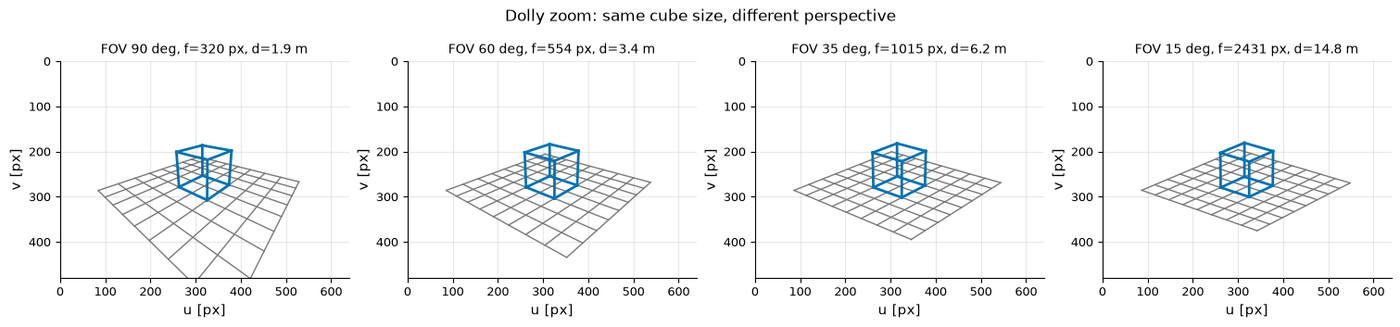

,fov_x_deg,f_px,distance_m,mean_vertical_edge_px,near_far_edge_ratio
0,90.0,320.000,1.943,77.509,1.331
1,60.0,554.256,3.365,76.807,1.178
2,35.0,1014.910,6.162,76.567,1.093
3,15.0,2430.641,14.756,76.483,1.038


In [4]:
# --- Dolly zoom: change the FOV and move the camera so the cube keeps its image size ---
# The camera moves along the same viewing ray; distance scales with the focal length f.
direction = (eye - target) / np.linalg.norm(eye - target)
d_ref, f_ref = np.linalg.norm(eye - target), cam.fx
vertical = np.array([abs(s[0, 2] - s[1, 2]) > 1e-9 for s in cube])  # the 4 vertical cube edges
dolly_rows = []
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
for ax, fov in zip(axes, [90.0, 60.0, 35.0, 15.0]):
    cam_f = geometry.PinholeCamera.from_fov(640, 480, fov_x_deg=fov)
    dist_m = d_ref * cam_f.fx / f_ref
    T_cw_f = geometry.invert_T(geometry.look_at(target + direction * dist_m, target))
    uv_c, z_c = project_segments(cube, cam_f.K, T_cw_f)
    draw_segments(ax, *project_segments(floor, cam_f.K, T_cw_f), cam_f, viz.color(7, True), 1.0)
    draw_segments(ax, uv_c, z_c, cam_f, viz.color(0, True), 2.0)
    lengths = np.linalg.norm(uv_c[vertical, 1] - uv_c[vertical, 0], axis=1)  # px
    dolly_rows.append({"fov_x_deg": fov, "f_px": cam_f.fx, "distance_m": dist_m,
                       "mean_vertical_edge_px": lengths.mean(),
                       "near_far_edge_ratio": lengths.max() / lengths.min()})
    ax.set_title(f"FOV {fov:.0f} deg, f={cam_f.fx:.0f} px, d={dist_m:.1f} m", fontsize=10)
fig.suptitle("Dolly zoom: same cube size, different perspective")
plt.show()
df_dolly = pd.DataFrame(dolly_rows).round(3)
results["dolly_zoom"] = dolly_rows
df_dolly

### 1.2 Check against OpenCV, then add lens distortion

`cv2.projectPoints` implements the same model plus the Brown-Conrady lens distortion applied on the
normalised plane ($r^2 = x^2 + y^2$):

$$
\begin{aligned}
x_d &= x\,(1 + k_1 r^2 + k_2 r^4 + k_3 r^6) + 2p_1 x y + p_2 (r^2 + 2x^2) \\
y_d &= y\,(1 + k_1 r^2 + k_2 r^4 + k_3 r^6) + p_1 (r^2 + 2y^2) + 2 p_2 x y
\end{aligned}
\qquad u = f_x x_d + c_x,\; v = f_y y_d + c_y .
$$

$k_1 < 0$ pulls points towards the centre (barrel distortion, typical for wide-angle lenses),
$k_1 > 0$ pushes them out (pincushion). OpenCV takes the rotation as a Rodrigues vector `rvec`
(axis times angle). Note for OpenCV 5: `projectPoints` returns an `(N, 1, 2)` array.

cv2.projectPoints output shape: (60, 1, 2) | max |ours - OpenCV| = 1.14e-13 px


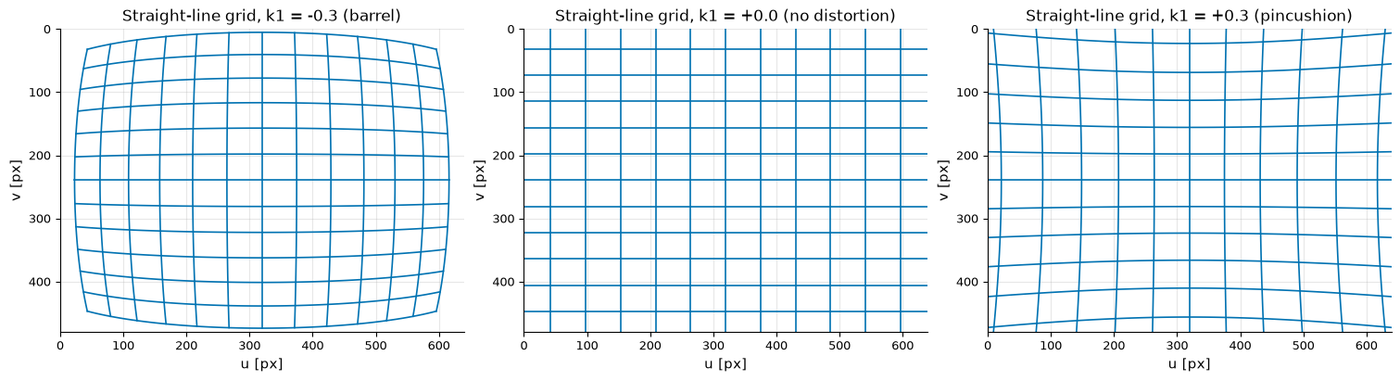

In [5]:
# --- Verify our projection against cv2.projectPoints, then visualise radial distortion ---
# rvec/tvec are the world->camera extrinsics in OpenCV's Rodrigues representation.
P_w = np.concatenate([cube.reshape(-1, 3), floor.reshape(-1, 3)])
rvec, _ = cv2.Rodrigues(T_cw[:3, :3])
uv_cv = cv2.projectPoints(P_w, rvec, T_cw[:3, 3], cam.K, np.zeros(5))[0]
uv_ours, _ = geometry.project_points(P_w, cam.K, T_cw)
max_diff = np.abs(uv_cv.reshape(-1, 2) - uv_ours).max()
results["projection_max_abs_diff_px"] = float(max_diff)
print(f"cv2.projectPoints output shape: {uv_cv.shape} | max |ours - OpenCV| = {max_diff:.2e} px")

# A fronto-parallel grid 2 m in front of the camera, sampled densely so curved lines are visible.
xs, ys = np.arange(-1.2, 1.21, 0.2), np.arange(-0.9, 0.91, 0.15)
plane = [[[x, -0.9, 2.0], [x, 0.9, 2.0]] for x in xs] + [[[-1.2, y, 2.0], [1.2, y, 2.0]] for y in ys]
plane = np.array(plane)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.9))
for ax, k1 in zip(axes, [-0.3, 0.0, 0.3]):
    dist = np.array([k1, 0.0, 0.0, 0.0, 0.0])
    draw_segments(ax, *project_segments(plane, cam.K, np.eye(4), n=60, dist=dist), cam,
                  viz.color(0, True), 1.2)
    name = "barrel" if k1 < 0 else "pincushion" if k1 > 0 else "no distortion"
    ax.set_title(f"Straight-line grid, k1 = {k1:+.1f} ({name})")
plt.show()

## 2. Digital images from a real robot camera

The TUM RGB-D benchmark was recorded with a handheld Microsoft Kinect (640x480 RGB at 30 Hz).
Handheld motion causes **motion blur** on many frames, which hurts every later step (features,
calibration, detection). A cheap and widely used sharpness score is the **variance of the Laplacian**:

$$ S = \operatorname{Var}\left(\nabla^2 I\right), \qquad \nabla^2 I = \frac{\partial^2 I}{\partial x^2} + \frac{\partial^2 I}{\partial y^2} . $$

Blur removes high frequencies, so the Laplacian response (a high-pass filter) gets weaker. The score also
depends on how much texture the scene has, so it is only meaningful **relative** to nearby frames of the
same sequence (e.g. for keyframe selection).

573 associated frames, scored 191 | sharpest #129 (S=692), blurriest #252 (S=58)


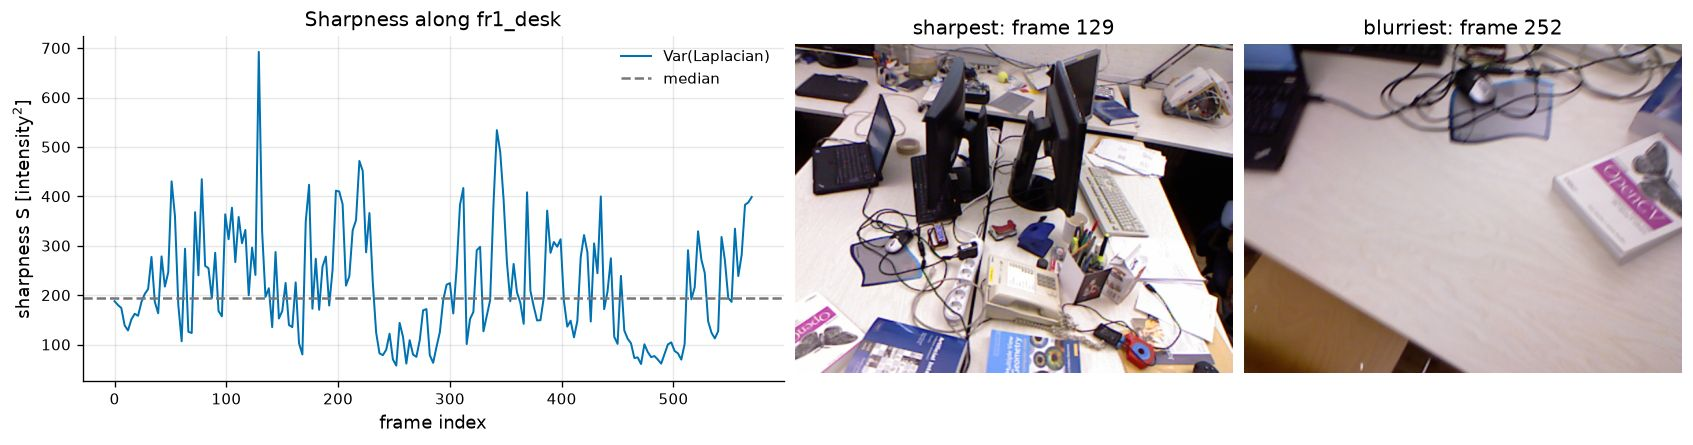

In [6]:
# --- Score every 3rd frame of fr1_desk with the variance of the Laplacian; keep the sharpest ---
seq = tum.load_sequence(TUM_DIR)
frame_ids = np.arange(0, len(seq), 3)
sharpness = np.array([
    cv2.Laplacian(cv2.cvtColor(seq.rgb(i), cv2.COLOR_RGB2GRAY), cv2.CV_64F).var() for i in frame_ids
])
best_id, worst_id = int(frame_ids[sharpness.argmax()]), int(frame_ids[sharpness.argmin()])
img = seq.rgb(best_id)  # RGB uint8, (480, 640, 3)
results["sharpness"] = {"frames_scored": len(frame_ids), "best_frame": best_id,
                        "best_score": float(sharpness.max()), "worst_frame": worst_id,
                        "worst_score": float(sharpness.min()),
                        "median_score": float(np.median(sharpness))}
print(f"{len(seq)} associated frames, scored {len(frame_ids)} | sharpest #{best_id} "
      f"(S={sharpness.max():.0f}), blurriest #{worst_id} (S={sharpness.min():.0f})")

fig = plt.figure(figsize=(14, 3.6))
gs = fig.add_gridspec(1, 3, width_ratios=[1.6, 1, 1])
ax = fig.add_subplot(gs[0])
ax.plot(frame_ids, sharpness, color=viz.color(0, True), lw=1.2, label="Var(Laplacian)")
ax.axhline(np.median(sharpness), color=viz.color(7, True), ls="--", label="median")
ax.set_xlabel("frame index")
ax.set_ylabel("sharpness S [intensity$^2$]")
ax.set_title("Sharpness along fr1_desk")
ax.legend()
for k, (fid, title) in enumerate([(best_id, "sharpest"), (worst_id, "blurriest")]):
    a = fig.add_subplot(gs[k + 1])
    a.imshow(seq.rgb(fid))
    a.axis("off")
    a.set_title(f"{title}: frame {fid}")
show_jpeg(fig)

### 2.1 Colour spaces

- **RGB** channels are strongly correlated: all three scale with illumination.
- **HSV** separates chromaticity (hue $H$, saturation $S$) from brightness ($V = \max(R,G,B)$).
- **CIE Lab** is approximately perceptually uniform: $L$ is lightness, $a$ (green-red) and $b$ (blue-yellow) are colour-opponent axes.

OpenCV gotchas: `cv2.imread` returns **BGR** (cvlab's `read_image` converts to RGB), and for 8-bit
images hue is stored as degrees/2, i.e. in $[0, 180)$.

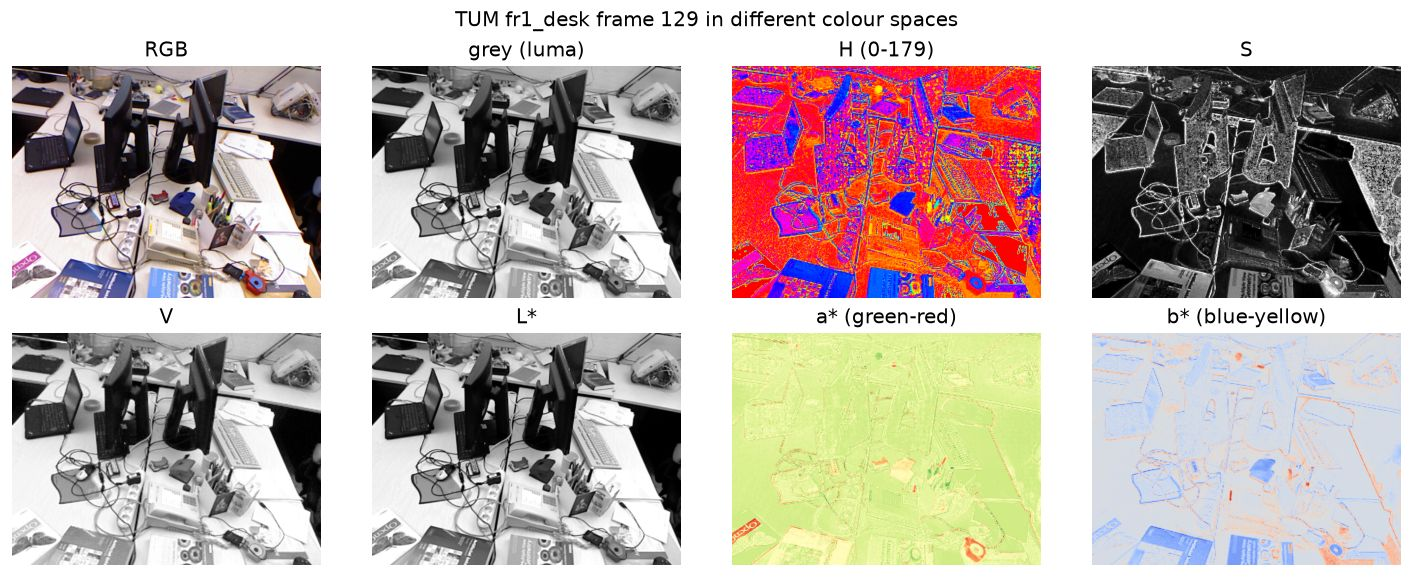

In [7]:
# --- Show the sharp frame in grey, HSV and Lab channels ---
# Each channel is displayed with its own colormap; hue is cyclic, so it gets the cyclic 'hsv' map.
gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)
lab = cv2.cvtColor(img, cv2.COLOR_RGB2Lab)
panels = [(img, "RGB", None), (gray, "grey (luma)", "gray"), (hsv[..., 0], "H (0-179)", "hsv"),
          (hsv[..., 1], "S", "gray"), (hsv[..., 2], "V", "gray"), (lab[..., 0], "L*", "gray"),
          (lab[..., 1], "a* (green-red)", "RdYlGn_r"), (lab[..., 2], "b* (blue-yellow)", "coolwarm")]
fig, axes = plt.subplots(2, 4, figsize=(12, 4.7))
for ax, (im, title, cmap) in zip(axes.flat, panels):
    ax.imshow(im, cmap=cmap)
    ax.set_title(title)
    ax.axis("off")
fig.suptitle(f"TUM fr1_desk frame {best_id} in different colour spaces")
show_jpeg(fig)

### 2.2 Why hue thresholds survive exposure changes

If the exposure changes by a factor $s$ ($I' = s\,I$), hue and saturation are unchanged (both are ratios
of channel differences) while $V$ scales by $s$. An RGB rule such as "blue > 120 and blue - red > 50"
uses absolute values, so it breaks as soon as the image gets darker. We segment the blue objects
(stapler, books, mouse pad) with both rules, darken the image, and measure the IoU with each rule's own
mask at $s = 1$. Expect HSV to degrade too once dark pixels fall under its $V \ge 40$ floor or
8-bit quantisation makes hue noisy.

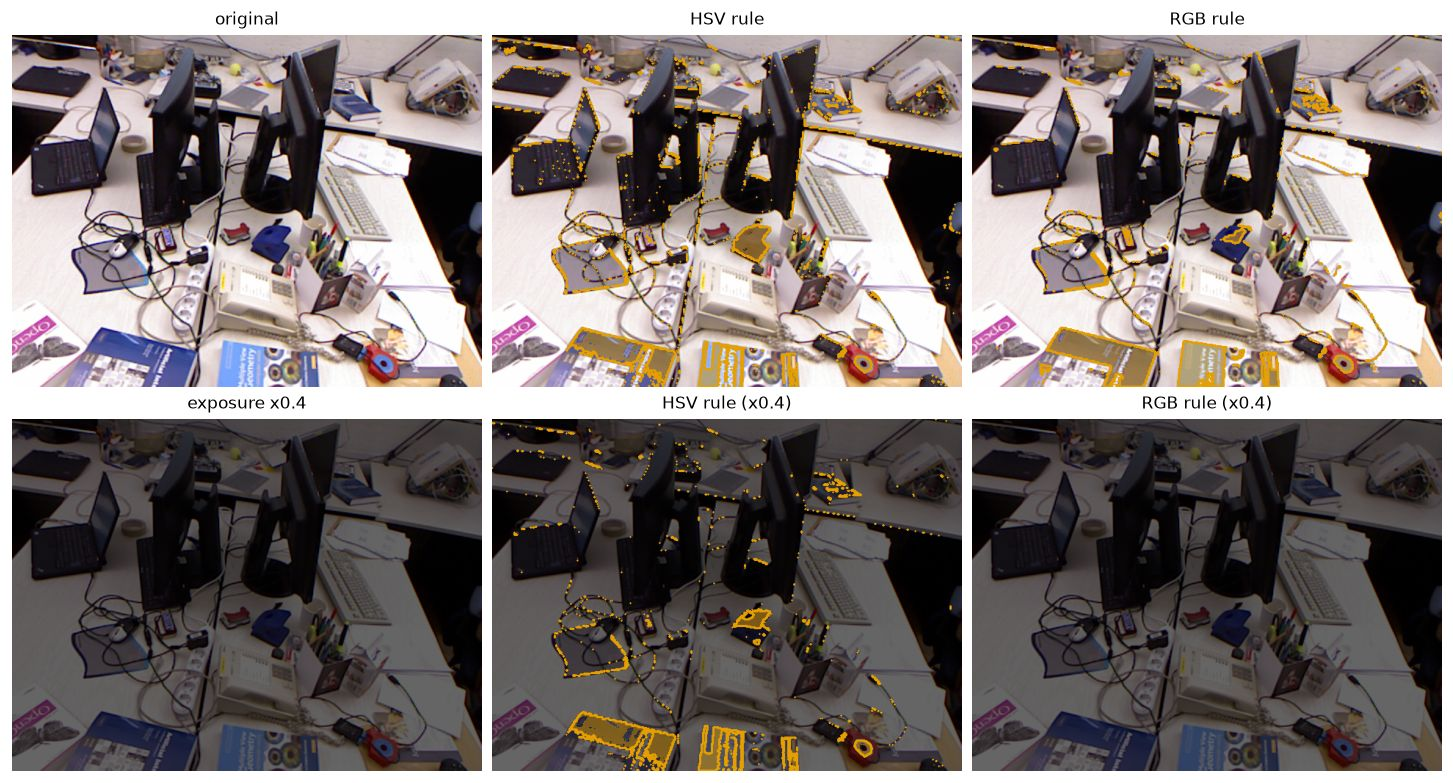

,brightness_scale,iou_hsv,iou_rgb
0,1.0,1.000,1.000
1,0.8,0.949,0.584
2,0.6,0.887,0.244
3,0.5,0.834,0.168
4,0.4,0.727,0.000
5,0.3,0.587,0.000
6,0.2,0.190,0.000


In [8]:
# --- Blue-object masks with an HSV rule and an RGB rule under simulated exposure changes ---
def mask_hsv(x):
    h = cv2.cvtColor(x, cv2.COLOR_RGB2HSV)
    return cv2.inRange(h, (100, 120, 40), (125, 255, 255)) > 0  # hue 200-250 deg, saturated

def mask_rgb(x):
    x = x.astype(np.int16)
    return (x[..., 2] > 120) & (x[..., 2] - x[..., 0] > 50) & (x[..., 2] - x[..., 1] > 30)

ref_hsv, ref_rgb = mask_hsv(img), mask_rgb(img)
scales = [1.0, 0.8, 0.6, 0.5, 0.4, 0.3, 0.2]
iou_rows = []
for s in scales:
    dark = np.clip(img.astype(np.float32) * s, 0, 255).astype(np.uint8)
    iou_rows.append({"brightness_scale": s, "iou_hsv": metrics.mask_iou(mask_hsv(dark), ref_hsv),
                     "iou_rgb": metrics.mask_iou(mask_rgb(dark), ref_rgb)})
df_color = pd.DataFrame(iou_rows)
results["color_threshold_iou"] = iou_rows

dark = np.clip(img.astype(np.float32) * 0.4, 0, 255).astype(np.uint8)
orange = [viz.color(1)]  # high-contrast overlay colour for blue objects
fig = viz.show_images([img, viz.overlay_masks(img, mask_hsv(img), colors=orange),
                       viz.overlay_masks(img, mask_rgb(img), colors=orange), dark,
                       viz.overlay_masks(dark, mask_hsv(dark), colors=orange),
                       viz.overlay_masks(dark, mask_rgb(dark), colors=orange)],
                      ["original", "HSV rule", "RGB rule", "exposure x0.4", "HSV rule (x0.4)", "RGB rule (x0.4)"],
                      ncols=3, size=4.0)
show_jpeg(fig)
df_color.round(3)

### 2.3 Sampling and aliasing

A digital image samples the continuous image on a grid. By the Nyquist-Shannon theorem, a signal sampled
with spacing 1 px can only represent frequencies below $0.5$ cycles/px; downsampling by $k$ lowers that
limit to $0.5/k$. Frequencies above it do not vanish, they **fold back** as false low-frequency patterns
(moire). The fix is to low-pass filter before subsampling.

A **zone plate** $I(r) = \tfrac12 + \tfrac12\cos(\pi r^2 / N)$ has local frequency $r/N$ cycles/px, growing
linearly from the centre, so it shows every frequency at once. We downsample a $512^2$ plate by $k=4$
and measure (a) the residual contrast (standard deviation) where the original frequency is far above the new
Nyquist limit (ideal: 0, flat grey) and (b) the contrast at low frequencies that should be kept
(ideal: $0.5/\sqrt2 = 0.354$).

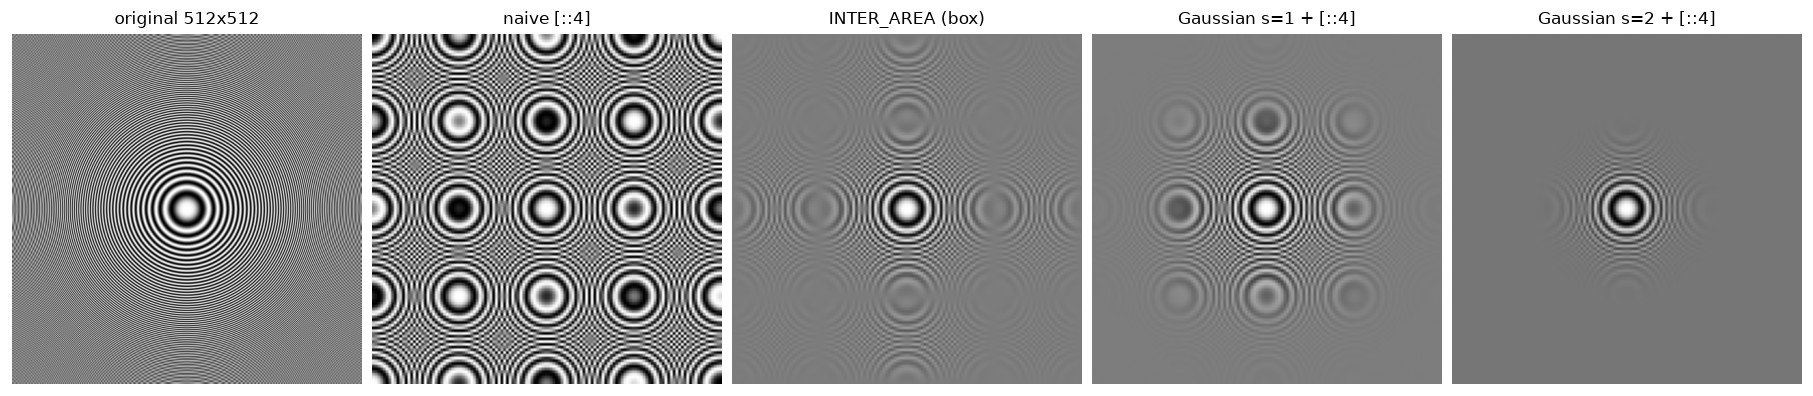

,method,aliased_contrast,passband_contrast
0,naive [::4],0.353,0.359
1,INTER_AREA (box),0.049,0.342
2,Gaussian s=1 + [::4],0.061,0.345
3,Gaussian s=2 + [::4],0.004,0.307


In [9]:
# --- Downsample a zone plate by 4 with and without low-pass filtering ---
N, k = 512, 4
yy, xx = np.mgrid[0:N, 0:N] - N / 2 + 0.5
zone = (0.5 + 0.5 * np.cos(np.pi * (xx**2 + yy**2) / N)).astype(np.float32)
methods = {
    "naive [::4]": zone[k // 2::k, k // 2::k],
    "INTER_AREA (box)": cv2.resize(zone, (N // k, N // k), interpolation=cv2.INTER_AREA),
    "Gaussian s=1 + [::4]": cv2.GaussianBlur(zone, (0, 0), 1.0)[k // 2::k, k // 2::k],
    "Gaussian s=2 + [::4]": cv2.GaussianBlur(zone, (0, 0), 2.0)[k // 2::k, k // 2::k],
}
yd, xd = np.mgrid[0:N // k, 0:N // k] - N / (2 * k) + 0.5
r_orig = np.hypot(xd, yd) * k                    # radius in original pixels
alias_band = (r_orig > 96) & (r_orig < N / 2)    # original frequency 0.19-0.5 cyc/px >> new limit 0.125
pass_band = r_orig < 32                          # original frequency < 0.0625 cyc/px: should survive
alias_rows = [{"method": m, "aliased_contrast": float(im[alias_band].std()),
               "passband_contrast": float(im[pass_band].std())} for m, im in methods.items()]
results["aliasing"] = alias_rows
fig = viz.show_images([zone] + list(methods.values()), ["original 512x512"] + list(methods),
                      ncols=5, size=3.0, cmap="gray")
show_jpeg(fig, quality=90)
pd.DataFrame(alias_rows).round(3)

## 3. Linear filtering: convolution from scratch

Discrete 2D convolution with a $k \times k$ kernel:

$$ (I * h)(x, y) = \sum_{i=-r}^{r}\sum_{j=-r}^{r} h(i, j)\, I(x - i,\, y - j), \qquad k = 2r + 1, $$

costs $k^2$ multiply-adds per pixel. A kernel is **separable** if $h(i,j) = g(i)\,g(j)$ (rank 1). The Gaussian
$G_\sigma(x, y) = \frac{1}{2\pi\sigma^2}e^{-(x^2+y^2)/2\sigma^2} = g_\sigma(x)\,g_\sigma(y)$ is, so two 1D passes
cost only $2k$. We implement both in NumPy (as sums of shifted images, so NumPy does the per-pixel work),
check them against OpenCV and time them for growing $\sigma$ (kernel radius $r = \lceil 3\sigma \rceil$).

Details that matter: OpenCV's `filter2D` actually computes *correlation* (no kernel flip; identical for
symmetric kernels), and its default border mode `BORDER_REFLECT_101` equals NumPy's `np.pad(mode="reflect")`.

In [10]:
# --- Direct and separable convolution in NumPy, checked against cv2.GaussianBlur ---
def gaussian_kernel_1d(sigma):
    r = int(np.ceil(3 * sigma))
    x = np.arange(-r, r + 1)
    g = np.exp(-(x**2) / (2 * sigma**2))
    return g / g.sum()

def conv2d_direct(im, h):
    # k*k shifted copies of the padded image, each weighted by one kernel tap
    r = h.shape[0] // 2
    p = np.pad(im, r, mode="reflect")
    H, W = im.shape
    out = np.zeros_like(im)
    for dy in range(h.shape[0]):
        for dx in range(h.shape[1]):
            out += h[dy, dx] * p[dy:dy + H, dx:dx + W]
    return out

def conv2d_separable(im, g):
    # horizontal pass then vertical pass: 2k shifted copies instead of k*k
    r = len(g) // 2
    H, W = im.shape
    p = np.pad(im, ((0, 0), (r, r)), mode="reflect")
    tmp = sum(g[i] * p[:, i:i + W] for i in range(len(g)))
    p = np.pad(tmp, ((r, r), (0, 0)), mode="reflect")
    return sum(g[i] * p[i:i + H, :] for i in range(len(g)))

gray_f = gray.astype(np.float32) / 255.0  # (480, 640) in [0, 1]
g = gaussian_kernel_1d(2.0)
ref = cv2.GaussianBlur(gray_f, (len(g), len(g)), 2.0, borderType=cv2.BORDER_REFLECT_101)
errs = {"direct vs OpenCV": np.abs(conv2d_direct(gray_f, np.outer(g, g)) - ref).max(),
        "separable vs OpenCV": np.abs(conv2d_separable(gray_f, g) - ref).max(),
        "cv2.getGaussianKernel vs ours": np.abs(cv2.getGaussianKernel(len(g), 2.0).ravel() - g).max()}
results["conv_max_abs_error"] = {k: float(v) for k, v in errs.items()}
for name, e in errs.items():
    print(f"max abs difference, {name}: {e:.2e}")

max abs difference, direct vs OpenCV: 8.34e-07
max abs difference, separable vs OpenCV: 2.24e-07
max abs difference, cv2.getGaussianKernel vs ours: 2.78e-17


Now the cost. `cvlab.bench.benchmark` runs warm-up iterations first and reports the mean wall-clock time.
OpenCV is multi-threaded and SIMD-vectorised; our NumPy versions are single-threaded loops over shifted
copies, so the absolute numbers are not a fair language comparison. The **scaling** with $k$ is the point.

In [11]:
# --- Time direct vs separable vs OpenCV for growing Gaussian kernels ---
conv_rows = []
for sigma in [0.5, 1.0, 2.0, 3.0, 4.0, 6.0]:
    g = gaussian_kernel_1d(sigma)
    g32 = g.astype(np.float32)
    ks = len(g)
    t_direct = benchmark(conv2d_direct, gray_f, np.outer(g, g), warmup=1, iters=3, cuda=False)
    t_sep = benchmark(conv2d_separable, gray_f, g, warmup=1, iters=5, cuda=False)
    t_cvsep = benchmark(cv2.sepFilter2D, gray_f, -1, g32, g32, warmup=5, iters=50, cuda=False)
    t_cvgauss = benchmark(cv2.GaussianBlur, gray_f, (ks, ks), sigma, warmup=5, iters=50, cuda=False)
    conv_rows.append({"sigma": sigma, "kernel_size": ks, "numpy_direct_ms": t_direct["mean_ms"],
                      "numpy_separable_ms": t_sep["mean_ms"], "cv2_sepFilter2D_ms": t_cvsep["mean_ms"],
                      "cv2_GaussianBlur_ms": t_cvgauss["mean_ms"]})
df_conv = pd.DataFrame(conv_rows)
df_conv["direct/separable"] = df_conv["numpy_direct_ms"] / df_conv["numpy_separable_ms"]
results["conv_timing_640x480_float32"] = df_conv.to_dict("records")
df_conv.round(3)

,sigma,kernel_size,numpy_direct_ms,numpy_separable_ms,cv2_sepFilter2D_ms,cv2_GaussianBlur_ms,direct/separable
0,0.5,5,6.760,2.275,0.076,0.079,2.972
1,1.0,7,12.554,3.143,0.120,0.120,3.994
2,2.0,13,45.234,5.823,0.225,0.225,7.768
3,3.0,19,92.463,8.470,0.334,0.338,10.916
4,4.0,25,186.426,13.689,0.551,0.497,13.619
5,6.0,37,379.231,17.607,0.817,0.773,21.539


### 3.1 Non-linear filters and denoising

| filter | output pixel | strength | weakness |
|---|---|---|---|
| box $k\times k$ | mean of the window | fastest (running sums) | blurs edges, ringing in frequency |
| Gaussian $\sigma$ | weighted mean, weights $G_\sigma(\lVert p-q\rVert)$ | smooth frequency response | blurs edges |
| median $k\times k$ | median of the window | removes impulse (salt-and-pepper) noise, keeps step edges | slower, removes thin lines |
| bilateral | $\frac{1}{W_p}\sum_q G_{\sigma_s}(\lVert p-q\rVert)\,G_{\sigma_r}(\lvert I_p-I_q\rvert)\,I_q$ | edge-preserving smoothing | slower; fooled by outliers |
| non-local means | average of pixels with *similar patches* | strong on Gaussian noise | slowest |

Quality metrics against the clean image (`cvlab.metrics`):
$\mathrm{PSNR} = 10\log_{10}\frac{255^2}{\mathrm{MSE}}$ (dB, higher is better) and SSIM, which compares local
means, variances and covariance in an $11\times11$ Gaussian window (1 = identical). We corrupt the sharp frame
with Gaussian noise ($\sigma = 20$) and with 5% salt-and-pepper noise. Filter parameters are common textbook
defaults, not tuned per noise type.

In [12]:
# --- Corrupt the frame with two noise types and compare five denoisers (PSNR, SSIM, runtime) ---
noisy = {
    "gaussian s=20": np.clip(img + rng.normal(0, 20, img.shape), 0, 255).astype(np.uint8),
    "salt&pepper 5%": img.copy(),
}
u = rng.random(img.shape[:2])
noisy["salt&pepper 5%"][u < 0.025] = 0
noisy["salt&pepper 5%"][u > 0.975] = 255
filters = {
    "box 5x5": lambda x: cv2.blur(x, (5, 5)),
    "gaussian s=1.5": lambda x: cv2.GaussianBlur(x, (0, 0), 1.5),
    "median 5x5": lambda x: cv2.medianBlur(x, 5),
    "bilateral d=9": lambda x: cv2.bilateralFilter(x, 9, 50, 5),
    "nl-means h=15": lambda x: cv2.fastNlMeansDenoisingColored(x, None, 15, 15, 7, 21),
}
den_rows, outputs = [], {}
for nname, x in noisy.items():
    den_rows.append({"noise": nname, "filter": "(noisy input)", "psnr_db": metrics.psnr(x, img, 255),
                     "ssim": metrics.ssim(x / 255.0, img / 255.0), "time_ms": 0.0})
    for fname, fn in filters.items():
        out = fn(x)
        outputs[(nname, fname)] = out
        t = benchmark(fn, x, warmup=1, iters=3, cuda=False)["mean_ms"]
        den_rows.append({"noise": nname, "filter": fname, "psnr_db": metrics.psnr(out, img, 255),
                         "ssim": metrics.ssim(out / 255.0, img / 255.0), "time_ms": t})
df_den = pd.DataFrame(den_rows)
results["denoising"] = den_rows
df_den.round(3)

,noise,filter,psnr_db,ssim,time_ms
0,gaussian s=20,(noisy input),22.807,0.491,0.000
1,gaussian s=20,box 5x5,24.021,0.764,0.119
2,gaussian s=20,gaussian s=1.5,24.639,0.798,0.190
3,gaussian s=20,median 5x5,25.402,0.774,0.865
4,gaussian s=20,bilateral d=9,28.055,0.793,13.965
5,gaussian s=20,nl-means h=15,25.165,0.756,147.637
6,salt&pepper 5%,(noisy input),17.464,0.447,0.000
7,salt&pepper 5%,box 5x5,23.255,0.683,0.115
8,salt&pepper 5%,gaussian s=1.5,23.802,0.727,0.149
9,salt&pepper 5%,median 5x5,26.539,0.884,0.942


A zoomed crop makes the trade-offs visible: linear filters smear edges and leave impulse noise as
grey blobs, the median removes impulses almost perfectly, and the bilateral filter keeps edges but treats
salt-and-pepper outliers as "edges" worth preserving.

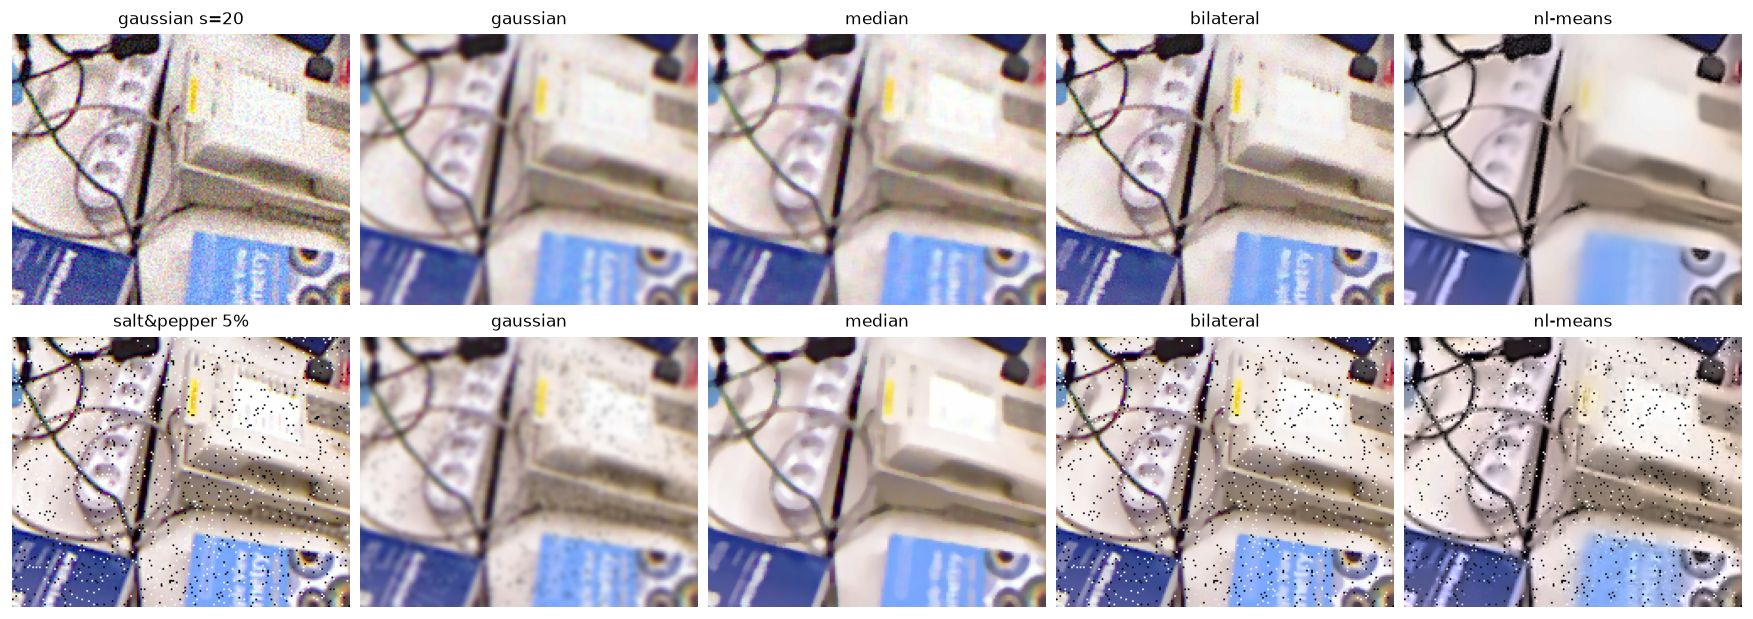

In [13]:
# --- Qualitative comparison on a 160x200 crop (rows 300-460, cols 180-380 of the frame) ---
crop = (slice(300, 460), slice(180, 380))
ims, titles = [], []
for nname in noisy:
    ims += [noisy[nname][crop]] + [outputs[(nname, f)][crop] for f in ["gaussian s=1.5", "median 5x5", "bilateral d=9", "nl-means h=15"]]
    titles += [f"{nname}"] + ["gaussian", "median", "bilateral", "nl-means"]
fig = viz.show_images(ims, titles, ncols=5, size=2.9)
show_jpeg(fig)

## 4. Gradients and edges

Edges are places where the intensity changes quickly, i.e. where the gradient
$\nabla I = (\partial I/\partial x, \partial I/\partial y)$ is large. The Sobel operator combines a central
difference with smoothing in the perpendicular direction:

$$ S_x = \begin{bmatrix}1\\2\\1\end{bmatrix}\begin{bmatrix}-1 & 0 & 1\end{bmatrix} =
\begin{bmatrix}-1&0&1\\-2&0&2\\-1&0&1\end{bmatrix}, \qquad
\lVert\nabla I\rVert = \sqrt{G_x^2 + G_y^2}, \qquad \theta = \operatorname{atan2}(G_y, G_x). $$

The gradient direction is perpendicular to the edge. Below the orientation is colour-coded (hue = angle)
and weighted by magnitude.

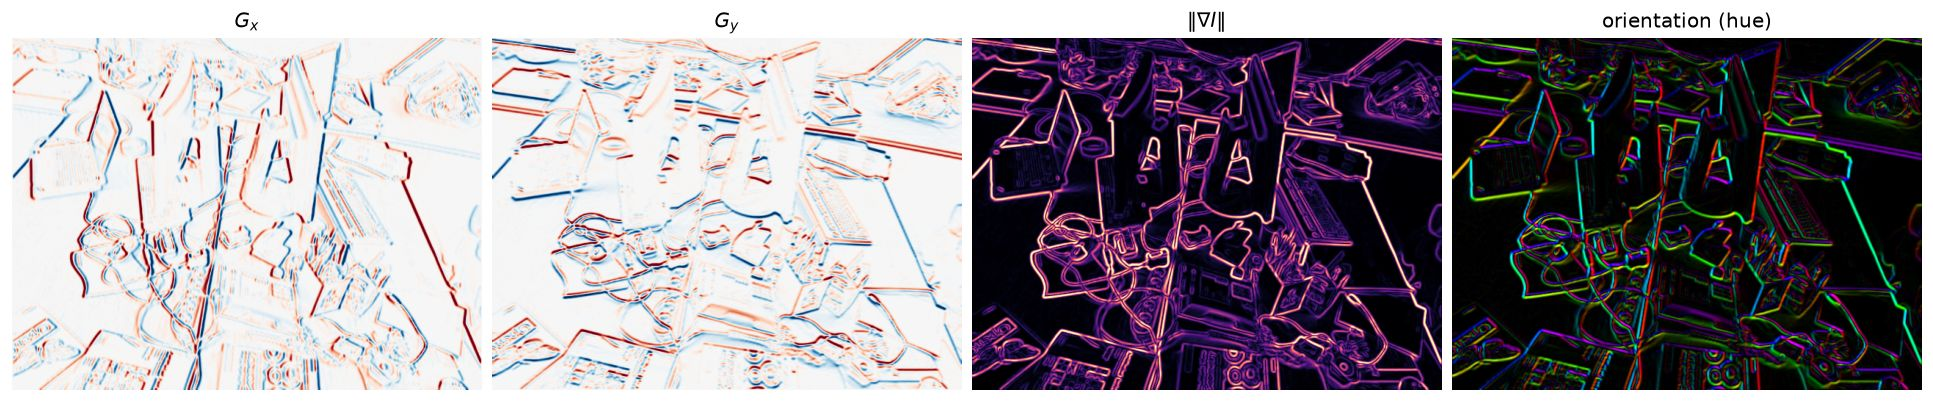

In [14]:
# --- Sobel gradients, magnitude and orientation of the (slightly blurred) frame ---
blurred = cv2.GaussianBlur(gray_f, (0, 0), 1.0)
gx = cv2.Sobel(blurred, cv2.CV_32F, 1, 0, ksize=3)  # dI/dx, intensity units per px
gy = cv2.Sobel(blurred, cv2.CV_32F, 0, 1, ksize=3)  # dI/dy (y points down)
mag, ang = cv2.cartToPolar(gx, gy, angleInDegrees=True)
hsv_vis = np.zeros((*gray.shape, 3), np.uint8)
hsv_vis[..., 0] = (ang / 2).astype(np.uint8)          # 0-360 deg -> 0-180 OpenCV hue
hsv_vis[..., 1] = 255
hsv_vis[..., 2] = np.clip(255 * mag / np.percentile(mag, 99), 0, 255).astype(np.uint8)
lim = np.percentile(np.abs(gx), 99)
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
for ax, im, title, kw in [(axes[0], gx, "$G_x$", dict(cmap="RdBu", vmin=-lim, vmax=lim)),
                          (axes[1], gy, "$G_y$", dict(cmap="RdBu", vmin=-lim, vmax=lim)),
                          (axes[2], mag, r"$\|\nabla I\|$", dict(cmap="magma", vmax=np.percentile(mag, 99))),
                          (axes[3], cv2.cvtColor(hsv_vis, cv2.COLOR_HSV2RGB), "orientation (hue)", {})]:
    ax.imshow(im, **kw)
    ax.set_title(title)
    ax.axis("off")
show_jpeg(fig)

### 4.1 The Canny edge detector

Canny (1986) turns the gradient into thin, connected edges:

1. **Smooth** with a Gaussian (suppresses noise; `cv2.Canny` does *not* do this, you must pre-blur),
2. **gradient** with Sobel ($L_1$ magnitude $|G_x|+|G_y|$ by default, Euclidean with `L2gradient=True`),
3. **non-maximum suppression**: keep a pixel only if its magnitude is a local maximum along the gradient direction (1-px-wide ridges),
4. **hysteresis**: pixels above `high` are strong edges; pixels between `low` and `high` survive only if connected to a strong edge.

Thresholds are in gradient-magnitude units of the 8-bit image, so they depend on contrast and on the blur.
A popular automatic choice uses the median intensity $m$: `low = 0.66 m`, `high = 1.33 m`.

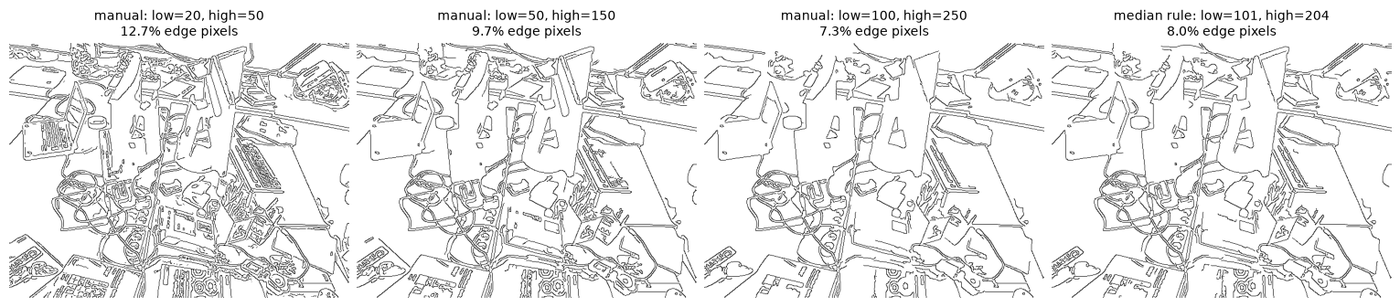

In [15]:
# --- Canny on the real frame with three manual threshold pairs and the median heuristic ---
gray_blur = cv2.GaussianBlur(gray, (0, 0), 1.0)
m = float(np.median(gray_blur))
settings = [(20, 50), (50, 150), (100, 250), (int(0.66 * m), int(1.33 * m))]
edge_maps, titles = [], []
for i, (lo, hi) in enumerate(settings):
    e = cv2.Canny(gray_blur, lo, hi)
    edge_maps.append(255 - e)  # black edges on white
    tag = "median rule" if i == 3 else "manual"
    titles.append(f"{tag}: low={lo}, high={hi}\n{(e > 0).mean() * 100:.1f}% edge pixels")
fig = viz.show_images(edge_maps, titles, ncols=4, size=3.8, cmap="gray")
plt.show()  # binary edge maps compress better as PNG than as JPEG

### 4.2 Measuring edge quality against ground truth

On real images we have no ground-truth edges, so we render a synthetic image with known region boundaries,
add Gaussian noise, and score Canny like a detector: a predicted edge pixel is a true positive if a ground-truth
edge lies within $\tau = 2$ px (and vice versa for recall), computed with distance transforms:

$$ P = \frac{\#\{\text{pred within }\tau\text{ of GT}\}}{\#\text{pred}}, \quad
R = \frac{\#\{\text{GT within }\tau\text{ of pred}\}}{\#\text{GT}}, \quad F_1 = \frac{2PR}{P+R}. $$

We sweep the high threshold (`low = 0.4 high`) for several pre-blur strengths $\sigma_b$.

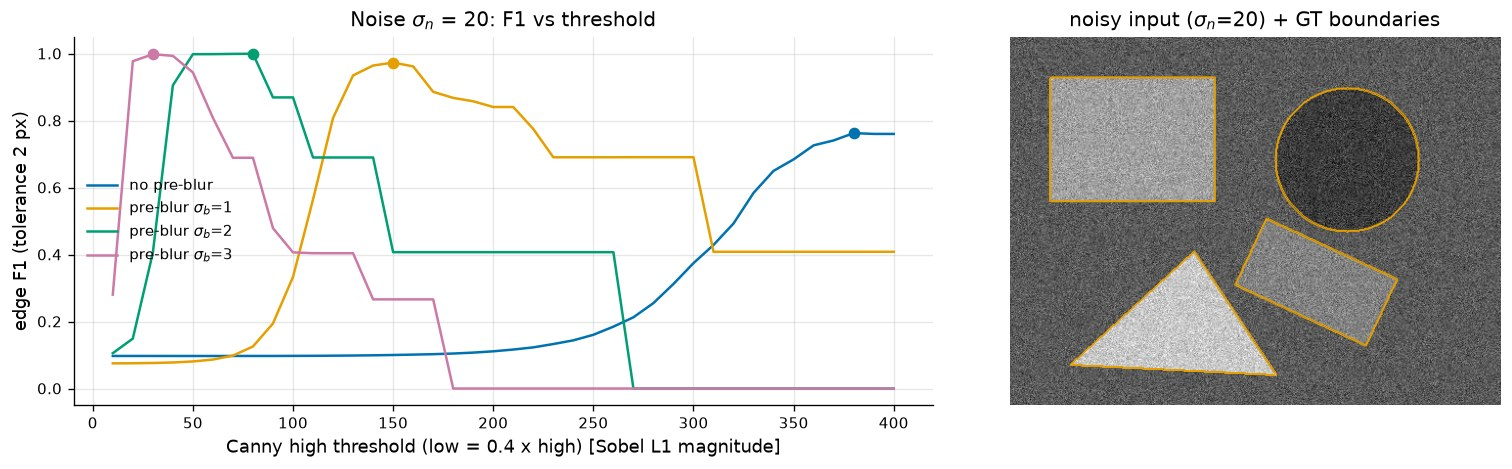

,best_f1,best_high
blur_0,0.762499,380.0
blur_1,0.973110,150.0
blur_2,0.999519,80.0
blur_3,0.998070,30.0


In [16]:
# --- Synthetic image with exact region labels -> ground-truth edges; Canny F1 vs threshold ---
def synth_scene(h=360, w=480):
    lab = np.zeros((h, w), np.uint8)
    cv2.rectangle(lab, (40, 40), (200, 160), 1, -1)
    cv2.circle(lab, (330, 120), 70, 2, -1)
    cv2.fillPoly(lab, [np.array([[60, 320], [180, 210], [260, 330]], np.int32)], 3)
    cv2.fillPoly(lab, [cv2.boxPoints(((300, 240), (140, 70), 25)).astype(np.int32)], 4)
    levels = np.array([90, 160, 60, 200, 130], np.float32)  # grey level of each region
    gt = np.zeros((h, w), bool)
    gt[:, :-1] |= lab[:, :-1] != lab[:, 1:]                   # label changes = boundaries
    gt[:-1, :] |= lab[:-1, :] != lab[1:, :]
    return levels[lab], gt

def edge_prf(pred, gt, tol=2.0):
    d_to_gt = cv2.distanceTransform((~gt).astype(np.uint8), cv2.DIST_L2, 3)
    d_to_pred = cv2.distanceTransform((~pred).astype(np.uint8), cv2.DIST_L2, 3)
    p = float((d_to_gt[pred] <= tol).mean()) if pred.any() else 0.0
    r = float((d_to_pred[gt] <= tol).mean()) if pred.any() else 0.0
    return p, r, 2 * p * r / (p + r + 1e-12)

def canny_f1(clean, gt, noise_sigma, blur_sigma, highs, seed=0):
    noisy_img = np.clip(clean + np.random.default_rng(seed).normal(0, noise_sigma, clean.shape), 0, 255)
    x = noisy_img.astype(np.uint8)
    if blur_sigma > 0:
        x = cv2.GaussianBlur(x, (0, 0), blur_sigma)
    return np.array([edge_prf(cv2.Canny(x, 0.4 * hi, hi) > 0, gt)[2] for hi in highs]), x

clean, gt_edges = synth_scene()
highs = np.arange(10, 401, 10)
blur_levels = [0.0, 1.0, 2.0, 3.0]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1.4, 1]})
sweep = {}
for i, bs in enumerate(blur_levels):
    f1, _ = canny_f1(clean, gt_edges, 20.0, bs, highs)
    sweep[bs] = f1
    axes[0].plot(highs, f1, color=viz.color(i, True), label=f"pre-blur $\\sigma_b$={bs:g}" if bs else "no pre-blur")
    axes[0].plot(highs[f1.argmax()], f1.max(), "o", color=viz.color(i, True))
axes[0].set_xlabel("Canny high threshold (low = 0.4 x high) [Sobel L1 magnitude]")
axes[0].set_ylabel("edge F1 (tolerance 2 px)")
axes[0].set_title("Noise $\\sigma_n$ = 20: F1 vs threshold")
axes[0].legend()
axes[1].imshow(np.clip(clean + np.random.default_rng(0).normal(0, 20, clean.shape), 0, 255), cmap="gray")
axes[1].contour(gt_edges, levels=[0.5], colors=[viz.color(1, True)], linewidths=0.6)
axes[1].set_title("noisy input ($\\sigma_n$=20) + GT boundaries")
axes[1].axis("off")
show_jpeg(fig, quality=88)
results["canny_threshold_sweep_noise20"] = {
    f"blur_{bs:g}": {"best_f1": float(f.max()), "best_high": int(highs[f.argmax()])} for bs, f in sweep.items()}
pd.DataFrame(results["canny_threshold_sweep_noise20"]).T

Finally we repeat the sweep for several noise levels and keep, for each pre-blur, the **best** F1 over all
thresholds (an optimistic "oracle threshold" upper bound; in practice thresholds are fixed in advance).

In [17]:
# --- Best-threshold Canny F1 vs noise level for each pre-blur strength ---
noise_levels = [0, 5, 10, 20, 30, 40]
canny_rows = []
for ns in noise_levels:
    for bs in blur_levels:
        f1, _ = canny_f1(clean, gt_edges, ns, bs, highs, seed=1)
        canny_rows.append({"noise_sigma": ns, "blur_sigma": bs, "best_f1": float(f1.max()),
                           "best_high": int(highs[f1.argmax()])})
df_canny = pd.DataFrame(canny_rows)
results["canny_noise_sweep"] = canny_rows
df_canny.pivot(index="noise_sigma", columns="blur_sigma", values="best_f1").round(3)

blur_sigma,0.0,1.0,2.0,3.0
noise_sigma,,,,
0,1.000,1.000,1.000,0.992
5,1.000,1.000,1.000,0.998
10,0.990,1.000,1.000,0.998
20,0.756,0.963,0.998,0.998
30,0.197,0.758,0.955,0.985
40,0.112,0.679,0.861,0.962


## Results

All numbers below were measured in this notebook on the CPU of the test machine (Intel Core Ultra 9 275HX;
the GPU listed in the setup cell is not used here). The summary figure collects the four quantitative
experiments; it is also saved to `assets/01_classical_cv/` for the project README.

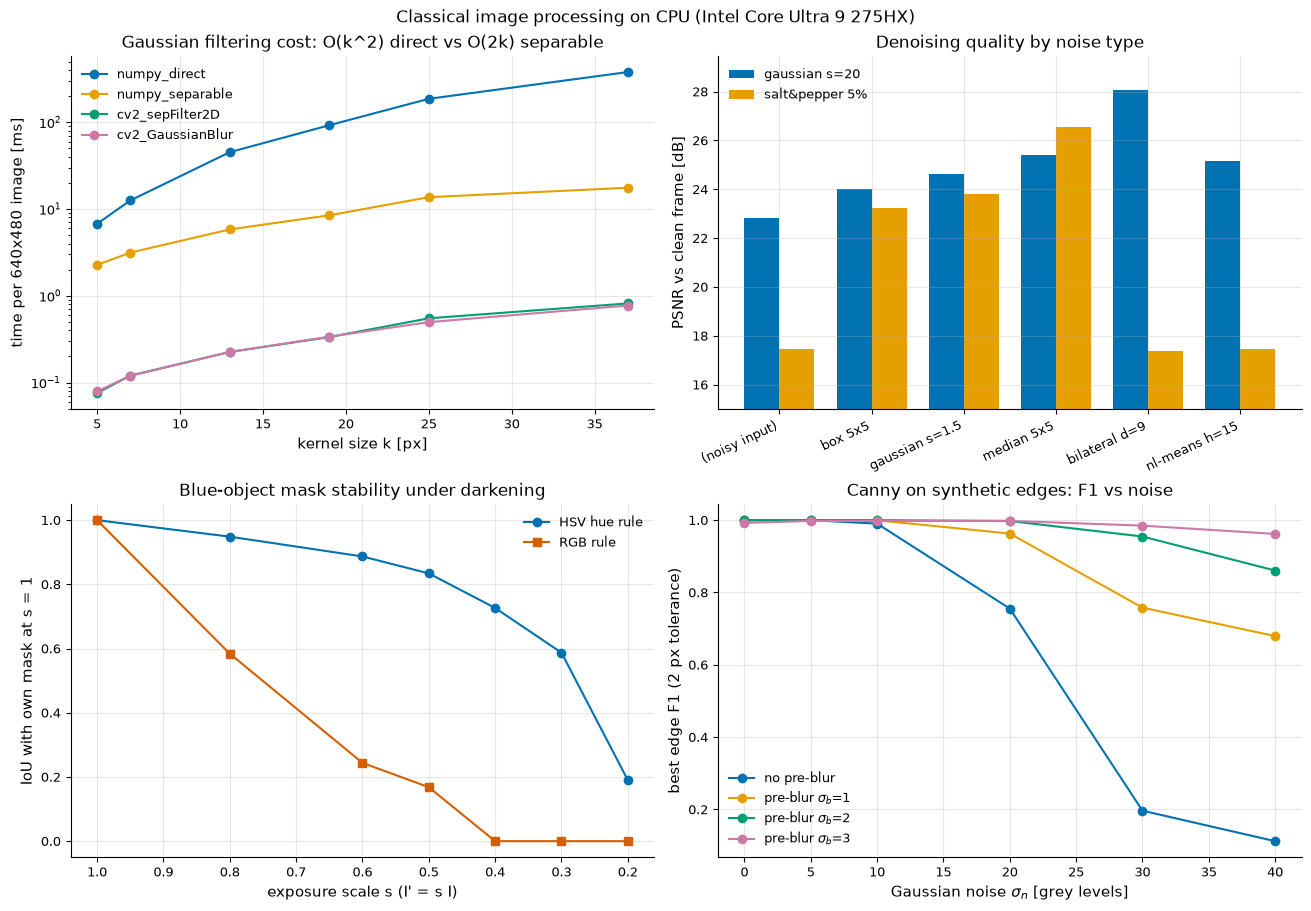

In [18]:
# --- Summary figure: convolution cost, denoising quality, colour robustness, edge F1 ---
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
ax = axes[0, 0]
for i, col in enumerate(["numpy_direct_ms", "numpy_separable_ms", "cv2_sepFilter2D_ms", "cv2_GaussianBlur_ms"]):
    ax.plot(df_conv["kernel_size"], df_conv[col], "o-", color=viz.color(i, True), label=col.replace("_ms", ""))
ax.set_yscale("log")
ax.set_xlabel("kernel size k [px]")
ax.set_ylabel("time per 640x480 image [ms]")
ax.set_title("Gaussian filtering cost: O(k^2) direct vs O(2k) separable")
ax.legend()

ax = axes[0, 1]
piv = df_den.pivot(index="filter", columns="noise", values="psnr_db")
order = ["(noisy input)", "box 5x5", "gaussian s=1.5", "median 5x5", "bilateral d=9", "nl-means h=15"]
piv = piv.loc[order]
xpos = np.arange(len(piv))
for j, col in enumerate(piv.columns):
    ax.bar(xpos + (j - 0.5) * 0.38, piv[col], width=0.38, color=viz.color(j, True), label=col)
ax.set_xticks(xpos, piv.index, rotation=25, ha="right")
ax.set_ylabel("PSNR vs clean frame [dB]")
ax.set_ylim(15, None)
ax.set_title("Denoising quality by noise type")
ax.legend()

ax = axes[1, 0]
ax.plot(df_color["brightness_scale"], df_color["iou_hsv"], "o-", color=viz.color(0, True), label="HSV hue rule")
ax.plot(df_color["brightness_scale"], df_color["iou_rgb"], "s-", color=viz.color(5, True), label="RGB rule")
ax.invert_xaxis()
ax.set_xlabel("exposure scale s (I' = s I)")
ax.set_ylabel("IoU with own mask at s = 1")
ax.set_title("Blue-object mask stability under darkening")
ax.legend()

ax = axes[1, 1]
for i, bs in enumerate(blur_levels):
    sub = df_canny[df_canny.blur_sigma == bs]
    ax.plot(sub["noise_sigma"], sub["best_f1"], "o-", color=viz.color(i, True),
            label=f"pre-blur $\\sigma_b$={bs:g}" if bs else "no pre-blur")
ax.set_xlabel("Gaussian noise $\\sigma_n$ [grey levels]")
ax.set_ylabel("best edge F1 (2 px tolerance)")
ax.set_title("Canny on synthetic edges: F1 vs noise")
ax.legend()
fig.suptitle("Classical image processing on CPU (Intel Core Ultra 9 275HX)")
viz.savefig(fig, PROJECT, "filtering_edges_summary")
plt.show()

For the README we also save a compact qualitative figure: the real frame, its Canny edges (median rule) and
the gradient-orientation map.

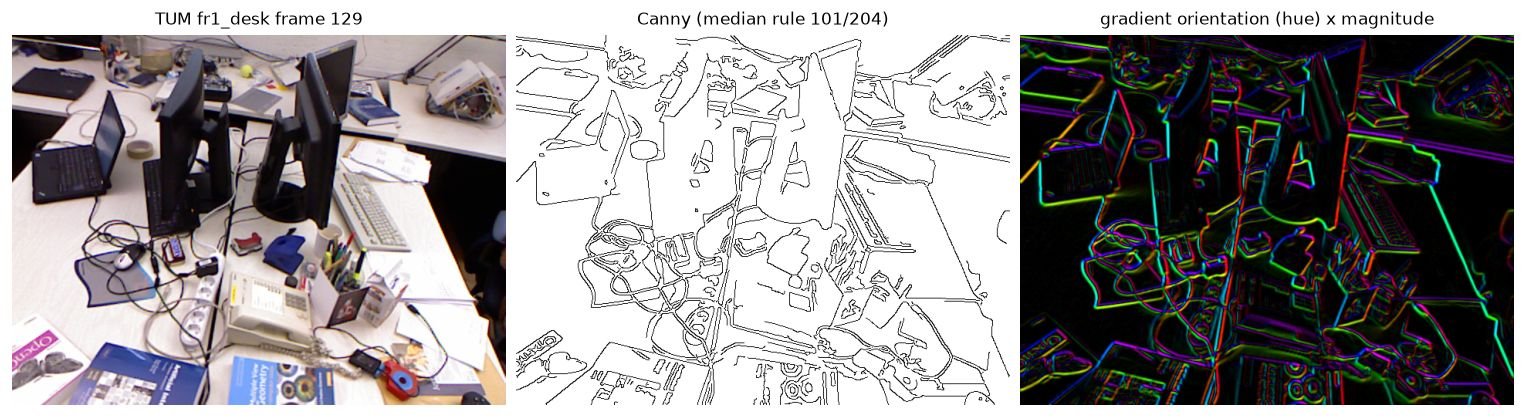

In [19]:
# --- Qualitative README figure: frame, Canny edges, gradient orientation ---
lo, hi = settings[3]
fig = viz.show_images([img, 255 - cv2.Canny(gray_blur, lo, hi), cv2.cvtColor(hsv_vis, cv2.COLOR_HSV2RGB)],
                      [f"TUM fr1_desk frame {best_id}", f"Canny (median rule {lo}/{hi})",
                       "gradient orientation (hue) x magnitude"], ncols=3, size=4.2, cmap="gray")
viz.savefig(fig, PROJECT, "edges_tum")
show_jpeg(fig)

The summary table collects the headline number of each experiment (full tables are above and in
`projects/01_classical_cv/results/nb01_filtering_edges.json`).

In [20]:
# --- Summary table of the measured headline numbers + save all results to JSON ---
k25 = df_conv[df_conv.kernel_size == 25].iloc[0]
best_den = df_den[df_den["filter"] != "(noisy input)"].loc[lambda d: d.groupby("noise")["psnr_db"].idxmax()]
c20 = df_canny[df_canny.noise_sigma == 20].set_index("blur_sigma")["best_f1"]
al = {r["method"]: r for r in alias_rows}
summary = [
    ("pinhole projection", "ours vs cv2.projectPoints", "max abs difference [px]", results["projection_max_abs_diff_px"]),
    ("dolly zoom", "FOV 90 deg", "near/far vertical edge ratio", df_dolly.iloc[0]["near_far_edge_ratio"]),
    ("dolly zoom", "FOV 15 deg", "near/far vertical edge ratio", df_dolly.iloc[-1]["near_far_edge_ratio"]),
    ("colour threshold", "exposure x0.4, HSV rule", "IoU vs s=1", df_color.set_index("brightness_scale").loc[0.4, "iou_hsv"]),
    ("colour threshold", "exposure x0.4, RGB rule", "IoU vs s=1", df_color.set_index("brightness_scale").loc[0.4, "iou_rgb"]),
    ("aliasing (zone plate, /4)", "naive subsampling", "aliased contrast (ideal 0)", al["naive [::4]"]["aliased_contrast"]),
    ("aliasing (zone plate, /4)", "Gaussian s=2 + subsampling", "aliased contrast (ideal 0)", al["Gaussian s=2 + [::4]"]["aliased_contrast"]),
    ("convolution k=25", "NumPy direct", "time [ms]", k25["numpy_direct_ms"]),
    ("convolution k=25", "NumPy separable", "time [ms]", k25["numpy_separable_ms"]),
    ("convolution k=25", "cv2.GaussianBlur", "time [ms]", k25["cv2_GaussianBlur_ms"]),
]
for _, r in best_den.iterrows():
    summary.append((f"denoising ({r['noise']})", f"best: {r['filter']}", "PSNR [dB]", r["psnr_db"]))
summary += [("Canny, noise s=20", "no pre-blur", "best F1", c20.loc[0.0]),
            ("Canny, noise s=20", "pre-blur s=2", "best F1", c20.loc[2.0])]
df_summary = pd.DataFrame(summary, columns=["experiment", "setting", "metric", "value"])
results["summary"] = df_summary.to_dict("records")
results["notebook_runtime_s"] = time.perf_counter() - T_START  # setup -> summary, CPU only
print(f"notebook runtime (setup to summary): {results['notebook_runtime_s']:.1f} s")
out = io.save_json(results, RESULTS_DIR / "nb01_filtering_edges.json")
print("saved", out.relative_to(ROOT))
df_summary.style.format({"value": "{:.4g}"}).hide(axis="index")

notebook runtime (setup to summary): 13.2 s
saved projects/01_classical_cv/results/nb01_filtering_edges.json


experiment,setting,metric,value
pinhole projection,ours vs cv2.projectPoints,max abs difference [px],1.137e-13
dolly zoom,FOV 90 deg,near/far vertical edge ratio,1.331
dolly zoom,FOV 15 deg,near/far vertical edge ratio,1.038
colour threshold,"exposure x0.4, HSV rule",IoU vs s=1,0.7265
colour threshold,"exposure x0.4, RGB rule",IoU vs s=1,0
"aliasing (zone plate, /4)",naive subsampling,aliased contrast (ideal 0),0.3532
"aliasing (zone plate, /4)",Gaussian s=2 + subsampling,aliased contrast (ideal 0),0.003868
convolution k=25,NumPy direct,time [ms],186.4
convolution k=25,NumPy separable,time [ms],13.69
convolution k=25,cv2.GaussianBlur,time [ms],0.4972


### Takeaways

- **The pinhole model is three lines of linear algebra.** Our projection matches `cv2.projectPoints` to floating-point
  precision (max difference in the table). Focal length and distance are *not* interchangeable: in the dolly zoom the cube
  keeps its size but the near/far edge ratio drops towards 1 as the FOV narrows, i.e. telephoto views flatten perspective.
- **Blur is common on a handheld or robot-mounted camera.** The variance of the Laplacian varies by roughly an order of
  magnitude along `fr1_desk`; it is a cheap keyframe filter, but it also responds to scene texture, so compare it only between
  neighbouring frames.
- **Hue is (nearly) exposure invariant, RGB thresholds are not.** At 40% exposure the HSV rule keeps most of its mask while
  the RGB rule loses it completely; both fail once pixels become too dark for a stable hue.
- **Always low-pass before downsampling.** Naive subsampling keeps almost the full contrast of frequencies it cannot
  represent (moire); a Gaussian with $\sigma \approx k/2$ removes most of it, at the price of some low-frequency contrast.
- **Separability changes the complexity class.** The direct NumPy convolution grows with $k^2$, the separable one with $k$;
  OpenCV is more than an order of magnitude faster again than our separable NumPy version (SIMD and multi-threading).
- **Match the filter to the noise.** The median filter wins clearly on salt-and-pepper noise, where the bilateral filter and
  non-local means do not improve on the input at all because they treat the impulses as structure worth keeping. On Gaussian
  noise the bilateral filter has the best PSNR and the plain Gaussian the best SSIM; non-local means with these default
  parameters over-smooths fine texture and is by far the slowest filter (see the time column). Parameters matter as much as the
  filter family.
- **Canny needs a pre-blur, and its thresholds interact with it.** Without smoothing, F1 collapses as noise grows; with
  $\sigma_b = 2$-$3$ it stays high even at strong noise, and the best threshold drops as the blur increases (smoothing also
  lowers the gradient magnitudes). The oracle-threshold F1 is an upper bound; a fixed threshold does worse.

## Exercises

Solutions: `projects/01_classical_cv/solutions/nb01_solutions.py` (run it from the repository root).

**Exercise 1: bilateral filter from scratch.** Implement
$\hat I_p = \frac{1}{W_p}\sum_{q \in \Omega_p} G_{\sigma_s}(\lVert p-q\rVert)\,G_{\sigma_r}(\lvert I_p - I_q\rvert)\,I_q$ for a
grey image (vectorise over shifts like `conv2d_direct`). Compare with `cv2.bilateralFilter(x, d=2r+1, sigmaColor, sigmaSpace)`
on a crop of the noisy frame: how close do you get (PSNR between the two outputs)?

In [21]:
# --- Exercise 1: bilateral filter from scratch ---
# TODO: implement the bilateral filter with a (2r+1)x(2r+1) window and compare it with cv2.bilateralFilter.
def bilateral_scratch(im, radius=4, sigma_s=5.0, sigma_r=50.0):
    # TODO: loop over the (dy, dx) shifts, weight each shifted image by the spatial and range Gaussians,
    #       accumulate the weighted sum and the normaliser W_p, and return their ratio.
    raise NotImplementedError

# Example usage once implemented:
# x = cv2.cvtColor(noisy["gaussian s=20"], cv2.COLOR_RGB2GRAY)[crop].astype(np.float32)
# print(metrics.psnr(bilateral_scratch(x), cv2.bilateralFilter(x, 9, 50, 5), 255))

**Exercise 2: unsharp masking vs. the blur detector.** Sharpen the *blurriest* frame with
$I_s = I + \alpha\,(I - G_\sigma * I)$ for $\alpha \in \{0.5, 1, 2\}$. How does the variance-of-Laplacian score change?
Does sharpening recover detail, or does it only fool the sharpness measure (look at the noise)?
OpenCV 5 note: `cv2.Laplacian` rejects a float32 input with a `CV_64F` output; use float64 input (or `CV_32F`).

In [22]:
# --- Exercise 2: unsharp masking and the variance-of-Laplacian score ---
# TODO: load seq.rgb(worst_id), convert to grey float, apply unsharp masking for several alphas,
#       and print the variance of the Laplacian of each result next to the sharpest frame's score.

**Exercise 3: Harris corners from Sobel gradients.** Build the structure tensor
$M = G_\sigma * \begin{bmatrix} G_x^2 & G_x G_y \\ G_x G_y & G_y^2\end{bmatrix}$ and the response
$R = \det M - \kappa\,(\operatorname{tr} M)^2$ with $\kappa = 0.04$. Compare your response map with `cv2.cornerHarris` and
check how many of the 200 strongest corners (after 5x5 non-maximum suppression) coincide.

In [23]:
# --- Exercise 3: Harris corner response from the structure tensor ---
# TODO: compute gx, gy with cv2.Sobel, smooth gx*gx, gx*gy, gy*gy with a Gaussian, form R,
#       then compare the top-200 local maxima with those of cv2.cornerHarris(gray_f, 3, 3, 0.04).